# Microfluidic Nanoparticle Particle-Size Prediction

This notebook completes the requested preprocessing, exploratory data analysis, regression modeling, evaluation, and feature-importance analysis.

**Predictors:** AIE concentration, F127 concentration, total flow rate (TFR), and flow-rate ratio (FRR).

**Target used:** `Particle_Size = initial_size_nm`. The workbook contains initial, mean, and final DLS sizes. The initial DLS size is used because it is the particle-size outcome most directly linked to the formulation and microfluidic settings; later sizes also contain time-dependent aggregation/stability effects. If your course specifically defines Particle_Size as the final DLS measurement, change `TARGET_SOURCE` to `final_size_nm` and rerun.

Experiments marked `valid_run = False` are excluded.

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
DATA_PATH = Path("aie_python_ready_template.xlsx")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/aie_python_ready_template.xlsx")
FIG_DIR = Path("particle_size_figures")
FIG_DIR.mkdir(exist_ok=True)
TARGET_SOURCE = "initial_size_nm"
print("Dataset:", DATA_PATH)
print("Target source:", TARGET_SOURCE)

Dataset: aie_python_ready_template.xlsx
Target source: initial_size_nm


## 1. Data preprocessing

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="model_dataset")

source_cols = {
    "aie_conc_mg_ml": "AIE_conc",
    "stabilizer_conc_mg_ml": "F127_conc",
    "tfr_ml_min": "TFR",
    "frr_aqueous_to_organic": "FRR",
    TARGET_SOURCE: "Particle_Size",
}
keep = list(source_cols) + ["valid_run", "experiment_id", "molecule_id"]
df = raw[keep].copy()
for c in source_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

valid = df["valid_run"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
n_raw = len(df)
n_invalid = int((~valid).sum())
df = df.loc[valid].dropna(subset=list(source_cols)).rename(columns=source_cols).copy()
features = ["AIE_conc", "F127_conc", "TFR", "FRR"]
target = "Particle_Size"

print(f"Rows in model_dataset: {n_raw}")
print(f"Invalid runs excluded: {n_invalid}")
print(f"Rows used for modeling: {len(df)}")
display(df[features + [target]].head())
print("Missing values after cleaning:")
display(df[features + [target]].isna().sum().to_frame("missing"))

Rows in model_dataset: 139
Invalid runs excluded: 4
Rows used for modeling: 135


,AIE_conc,F127_conc,TFR,FRR,Particle_Size
0,0.4,3.0,1.5,8.0,42.50
1,0.5,2.0,2.0,2.0,37.72
2,0.6,4.0,1.5,14.0,64.21
4,0.2,5.0,2.5,4.0,64.47
5,0.6,0.5,1.5,8.0,69.13


Missing values after cleaning:


,missing
AIE_conc,0
F127_conc,0
TFR,0
FRR,0
Particle_Size,0


## 2. Descriptive statistics and EDA

,count,mean,std,min,25%,50%,75%,max,skewness
AIE_conc,135.0,0.586,0.229,0.20,0.40,0.60,0.800,0.8,-0.624
F127_conc,135.0,2.552,2.141,0.00,0.00,2.00,5.000,5.0,0.017
TFR,135.0,1.915,0.899,1.00,1.00,1.50,3.000,3.0,0.189
FRR,135.0,8.452,5.132,1.00,3.00,10.00,14.000,14.0,-0.331
Particle_Size,135.0,78.928,65.584,31.16,47.31,59.63,76.215,488.9,3.828


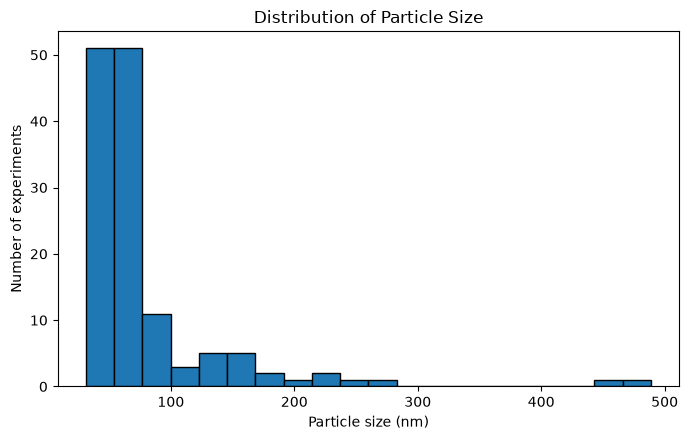

In [4]:
desc = df[features + [target]].describe().T
desc["skewness"] = df[features + [target]].skew()
display(desc.round(3))

plt.figure(figsize=(7, 4.5))
plt.hist(df[target], bins=20, edgecolor="black")
plt.xlabel("Particle size (nm)")
plt.ylabel("Number of experiments")
plt.title("Distribution of Particle Size")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_particle_size_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Feature correlations

Pearson correlation describes linear association, not causation. A nonlinear model can still exploit patterns that a simple correlation coefficient misses.

,AIE_conc,F127_conc,TFR,FRR,Particle_Size
AIE_conc,1.000,0.135,0.032,0.063,0.123
F127_conc,0.135,1.000,-0.046,-0.030,-0.197
TFR,0.032,-0.046,1.000,-0.229,-0.029
FRR,0.063,-0.030,-0.229,1.000,-0.288
Particle_Size,0.123,-0.197,-0.029,-0.288,1.000


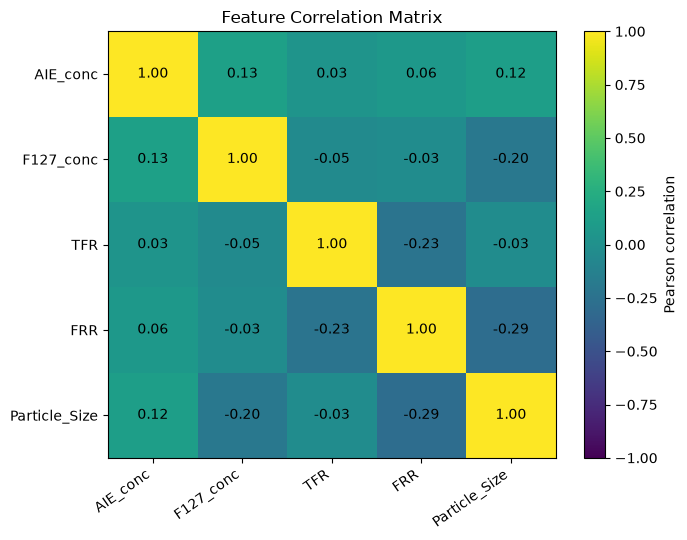

Correlation with Particle_Size:


,Pearson_r
FRR,-0.288
F127_conc,-0.197
AIE_conc,0.123
TFR,-0.029


In [5]:
corr = df[features + [target]].corr()
display(corr.round(3))

plt.figure(figsize=(7, 5.5))
im = plt.imshow(corr.values, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

print("Correlation with Particle_Size:")
display(corr[target].drop(target).sort_values(key=np.abs, ascending=False).to_frame("Pearson_r").round(3))

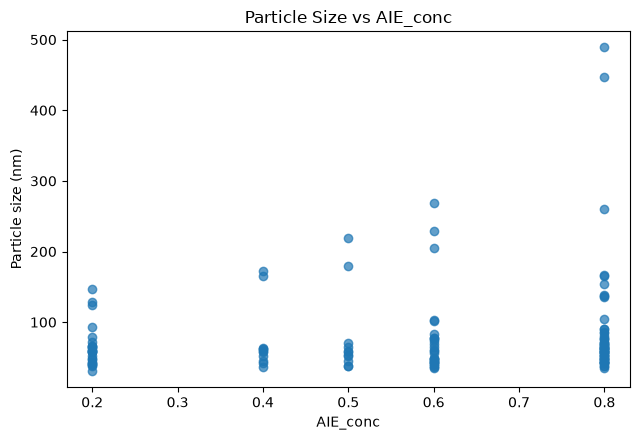

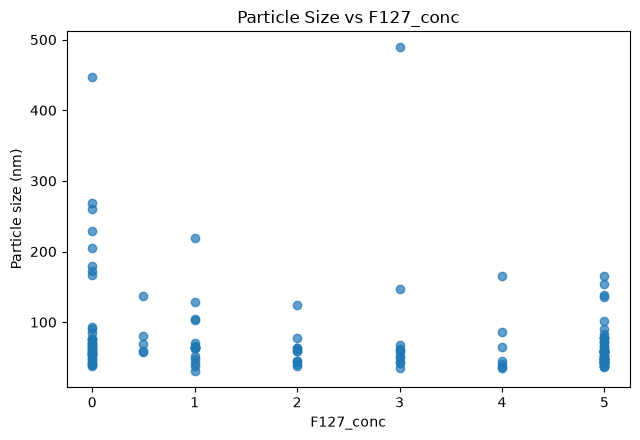

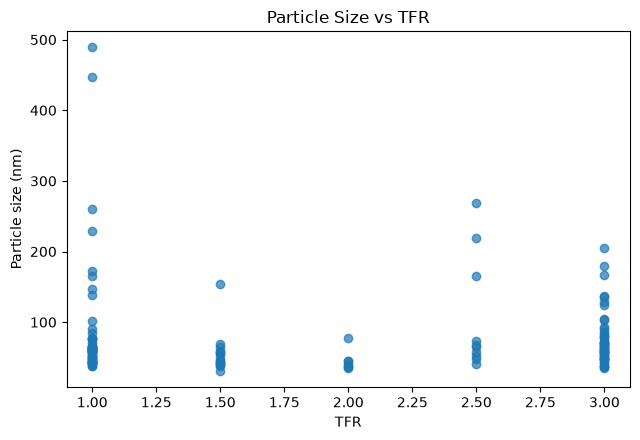

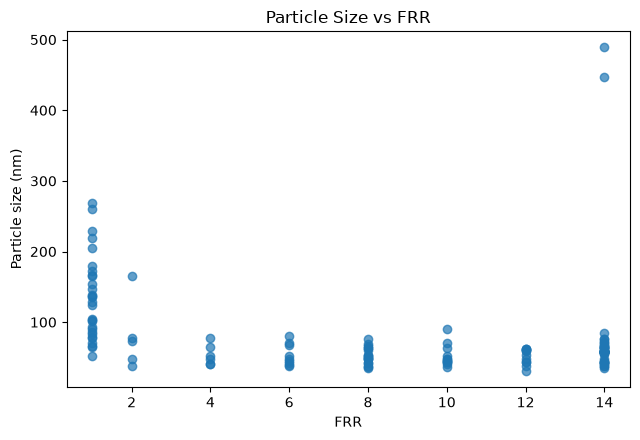

In [6]:
for i, feature in enumerate(features, start=1):
    plt.figure(figsize=(6.5, 4.5))
    plt.scatter(df[feature], df[target], alpha=0.7)
    plt.xlabel(feature)
    plt.ylabel("Particle size (nm)")
    plt.title(f"Particle Size vs {feature}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"03_{i}_{feature}_vs_particle_size.png", dpi=180, bbox_inches="tight")
    plt.show()

## 4. Compare regression models with 5-fold cross-validation

The dataset is small, so all valid observations are used efficiently through shuffled 5-fold cross-validation. The primary selection metric is MAE (lower is better); R² is also reported.

,Model,CV_R2_mean,CV_R2_std,CV_MAE_mean_nm,CV_MAE_std_nm
0,Gradient Boosting (Huber),0.440,0.328,22.369,8.053
1,SVR (RBF),0.271,0.243,26.389,7.181
2,Extra Trees,0.188,0.281,28.526,8.622
3,Random Forest,0.210,0.240,29.636,8.195
4,Ridge,0.107,0.152,35.030,4.583
5,Linear Regression,0.092,0.174,35.578,4.741


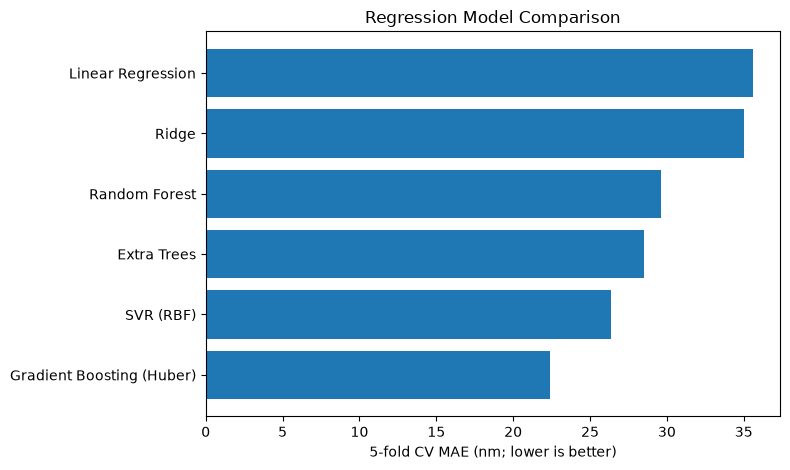

In [7]:
X = df[features].to_numpy(float)
y = df[target].to_numpy(float)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=10.0))]),
    "Random Forest": RandomForestRegressor(n_estimators=120, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=120, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "SVR (RBF)": Pipeline([("scale", StandardScaler()), ("model", SVR(C=100, epsilon=0.1))]),
    "Gradient Boosting (Huber)": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.02, max_depth=2,
        min_samples_leaf=4, loss="huber", random_state=RANDOM_STATE
    ),
}

results = []
for name, model in models.items():
    s = cross_validate(model, X, y, cv=kf,
                       scoring={"r2": "r2", "mae": "neg_mean_absolute_error"},
                       n_jobs=1)
    results.append({
        "Model": name,
        "CV_R2_mean": s["test_r2"].mean(),
        "CV_R2_std": s["test_r2"].std(),
        "CV_MAE_mean_nm": -s["test_mae"].mean(),
        "CV_MAE_std_nm": (-s["test_mae"]).std(),
    })
comparison = pd.DataFrame(results).sort_values("CV_MAE_mean_nm").reset_index(drop=True)
display(comparison.round(3))

plt.figure(figsize=(8, 4.8))
plot_df = comparison.sort_values("CV_MAE_mean_nm", ascending=True)
plt.barh(plot_df["Model"], plot_df["CV_MAE_mean_nm"])
plt.xlabel("5-fold CV MAE (nm; lower is better)")
plt.title("Regression Model Comparison")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_model_comparison_mae.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Final model evaluation

Gradient Boosting with Huber loss is selected because it has the lowest cross-validated MAE among the tested models. Huber loss also reduces the influence of unusually large particle-size observations.

5-fold CV R²:  0.440 ± 0.328
5-fold CV MAE: 22.37 ± 8.05 nm
Pooled out-of-fold R²:  0.269
Pooled out-of-fold MAE: 22.37 nm


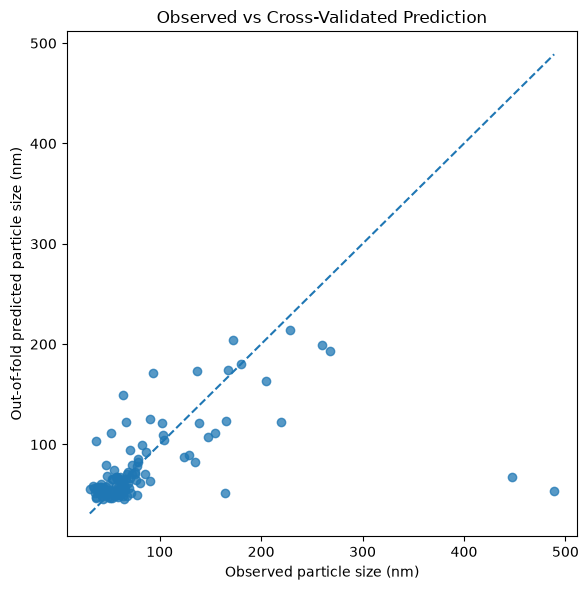

In [8]:
final_model = models["Gradient Boosting (Huber)"]
final_scores = cross_validate(final_model, X, y, cv=kf,
                              scoring={"r2": "r2", "mae": "neg_mean_absolute_error"},
                              n_jobs=1)
cv_r2_mean = final_scores["test_r2"].mean()
cv_r2_std = final_scores["test_r2"].std()
cv_mae_mean = -final_scores["test_mae"].mean()
cv_mae_std = (-final_scores["test_mae"]).std()

print(f"5-fold CV R²:  {cv_r2_mean:.3f} ± {cv_r2_std:.3f}")
print(f"5-fold CV MAE: {cv_mae_mean:.2f} ± {cv_mae_std:.2f} nm")

oof_pred = cross_val_predict(final_model, X, y, cv=kf, n_jobs=1)
oof_r2 = r2_score(y, oof_pred)
oof_mae = mean_absolute_error(y, oof_pred)
print(f"Pooled out-of-fold R²:  {oof_r2:.3f}")
print(f"Pooled out-of-fold MAE: {oof_mae:.2f} nm")

plt.figure(figsize=(6, 6))
plt.scatter(y, oof_pred, alpha=0.75)
lo = min(y.min(), oof_pred.min())
hi = max(y.max(), oof_pred.max())
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Observed particle size (nm)")
plt.ylabel("Out-of-fold predicted particle size (nm)")
plt.title("Observed vs Cross-Validated Prediction")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_observed_vs_predicted.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Relative importance of input parameters

Cross-validated permutation importance measures how much held-out MAE worsens when a feature is randomly disrupted. This is used as the primary importance measure. The final model's built-in tree importance is shown as a secondary check.

,Feature,CV_permutation_MAE_increase_nm,CV_permutation_std_nm,Tree_importance
3,FRR,19.141,2.441,0.776
1,F127_conc,4.502,2.347,0.145
2,TFR,1.184,1.326,0.031
0,AIE_conc,0.891,0.368,0.049


Strongest predictive parameter: FRR


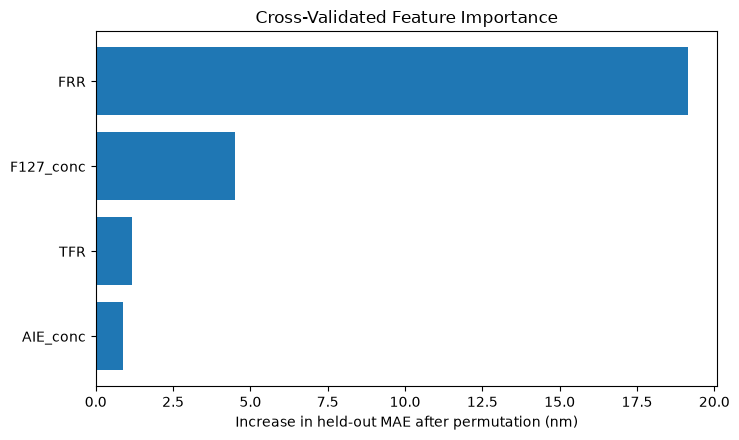

In [9]:
fold_importances = []
for train_idx, test_idx in kf.split(X):
    fold_model = GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.02, max_depth=2,
        min_samples_leaf=4, loss="huber", random_state=RANDOM_STATE
    )
    fold_model.fit(X[train_idx], y[train_idx])
    p = permutation_importance(
        fold_model, X[test_idx], y[test_idx],
        scoring="neg_mean_absolute_error", n_repeats=10,
        random_state=RANDOM_STATE, n_jobs=1
    )
    fold_importances.append(p.importances_mean)

perm = np.vstack(fold_importances)
final_model.fit(X, y)
importance = pd.DataFrame({
    "Feature": features,
    "CV_permutation_MAE_increase_nm": perm.mean(axis=0),
    "CV_permutation_std_nm": perm.std(axis=0),
    "Tree_importance": final_model.feature_importances_,
}).sort_values("CV_permutation_MAE_increase_nm", ascending=False)
display(importance.round(3))

strongest_feature = importance.iloc[0]["Feature"]
print("Strongest predictive parameter:", strongest_feature)

plt.figure(figsize=(7.5, 4.5))
plot_imp = importance.sort_values("CV_permutation_MAE_increase_nm", ascending=True)
plt.barh(plot_imp["Feature"], plot_imp["CV_permutation_MAE_increase_nm"])
plt.xlabel("Increase in held-out MAE after permutation (nm)")
plt.title("Cross-Validated Feature Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Save the fitted model

In [10]:
MODEL_PATH = Path("particle_size_gradient_boosting_model.joblib")
joblib.dump({"model": final_model, "features": features,
             "target": target, "target_source": TARGET_SOURCE}, MODEL_PATH)
print("Saved:", MODEL_PATH.resolve())

Saved: E:\Me\microfluidic_particle_size_project\particle_size_gradient_boosting_model.joblib


## 8. Short results summary

In [11]:
corr_target = corr[target].drop(target)
strongest_linear = corr_target.abs().idxmax()
summary = f"""
### Main findings

- **Data used:** {len(df)} valid experiments.
- **Particle size:** median **{df[target].median():.2f} nm**, mean **{df[target].mean():.2f} nm**, range **{df[target].min():.2f}–{df[target].max():.2f} nm**.
- **Strongest simple linear correlation:** **{strongest_linear}** with Pearson r = **{corr_target[strongest_linear]:.3f}**.
- **Best tested model:** **Gradient Boosting Regressor with Huber loss**.
- **5-fold cross-validation:** **R² = {cv_r2_mean:.3f} ± {cv_r2_std:.3f}** and **MAE = {cv_mae_mean:.2f} ± {cv_mae_std:.2f} nm**.
- **Strongest predictive parameter:** **{strongest_feature}**. Shuffling it raises held-out MAE by about **{importance.iloc[0]['CV_permutation_MAE_increase_nm']:.1f} nm** on average.
- **Feature ranking:** **FRR** is dominant, followed by **F127 concentration**; **TFR** and **AIE concentration** have substantially smaller predictive contributions in this four-variable model.

### Interpretation

The nonlinear model captures useful structure, but the moderate cross-validated R² and substantial fold-to-fold variability show that the four process variables do not explain all particle-size variation. The workbook contains several different AIE molecules, yet molecule identity is intentionally excluded to follow the four-input assignment specification. Therefore, this model should be interpreted as an interpolation model for the represented experiments, not as proof that it will generalize to a completely new AIE chemistry.
"""
display(Markdown(summary))
Path("particle_size_results_summary.md").write_text(summary, encoding="utf-8")


### Main findings

- **Data used:** 135 valid experiments.
- **Particle size:** median **59.63 nm**, mean **78.93 nm**, range **31.16–488.90 nm**.
- **Strongest simple linear correlation:** **FRR** with Pearson r = **-0.288**.
- **Best tested model:** **Gradient Boosting Regressor with Huber loss**.
- **5-fold cross-validation:** **R² = 0.440 ± 0.328** and **MAE = 22.37 ± 8.05 nm**.
- **Strongest predictive parameter:** **FRR**. Shuffling it raises held-out MAE by about **19.1 nm** on average.
- **Feature ranking:** **FRR** is dominant, followed by **F127 concentration**; **TFR** and **AIE concentration** have substantially smaller predictive contributions in this four-variable model.

### Interpretation

The nonlinear model captures useful structure, but the moderate cross-validated R² and substantial fold-to-fold variability show that the four process variables do not explain all particle-size variation. The workbook contains several different AIE molecules, yet molecule identity is intentionally excluded to follow the four-input assignment specification. Therefore, this model should be interpreted as an interpolation model for the represented experiments, not as proof that it will generalize to a completely new AIE chemistry.


1250